# **Análisis de factores de Detracción en la Facultad de Ciencias Sociales**

**Importar paquetes**

In [1]:
import pandas as pd
import os
import sys
from datetime import datetime
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, ConfusionMatrixDisplay, accuracy_score, confusion_matrix
import seaborn as sns

**Preparación del acceso al Drive**

In [2]:
from google.colab import drive
drive.mount('/content/drive')


# Get the current directory of the notebook
current_dir = os.getcwd()

# Construct the path to the utilidadesML directory (assuming it's in the same directory as the notebook)
utilidadesML_path = os.path.join(current_dir, "drive/MyDrive/Colab Notebooks")

# Add the utilidadesML directory to the Python path
sys.path.append(utilidadesML_path)

import utilidadesML as ml

Mounted at /content/drive


**Lectura de los datos**

In [3]:
from google.colab import drive
drive.mount('/content/drive')
estudiantes = pd.read_csv('/content/drive/MyDrive/Colab Notebooks/DATANPS2025.csv', sep=";")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


**Análisis de correlaciones para Detractores**

In [4]:
estudiantes_CSOCIALES = estudiantes[estudiantes['CAB3'] == 'Ciencias Sociales'].copy()
estudiantes_CSOCIALES.info()

<class 'pandas.core.frame.DataFrame'>
Index: 123 entries, 251 to 7896
Data columns (total 77 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   ID_COD                 123 non-null    int64  
 1   ID                     123 non-null    int64  
 2   X_CAMPUS               123 non-null    object 
 3   X_PERIODO              123 non-null    object 
 4   X_MODALIDAD            123 non-null    object 
 5   PROGRAMA               123 non-null    int64  
 6   X_FACULTAD             123 non-null    object 
 7   DESCRIPCION_PROGRAMA   123 non-null    object 
 8   PERIODO_ADMISION       123 non-null    int64  
 9   CATALOGO               123 non-null    int64  
 10  CICLO_ACTUAL           123 non-null    int64  
 11  CREDITOS_TOTAL         123 non-null    int64  
 12  CREDITOS_MATRICULADOS  123 non-null    int64  
 13  CACHIMBO               123 non-null    int64  
 14  CICLO_MUESTRA          123 non-null    object 
 15  REINCORP

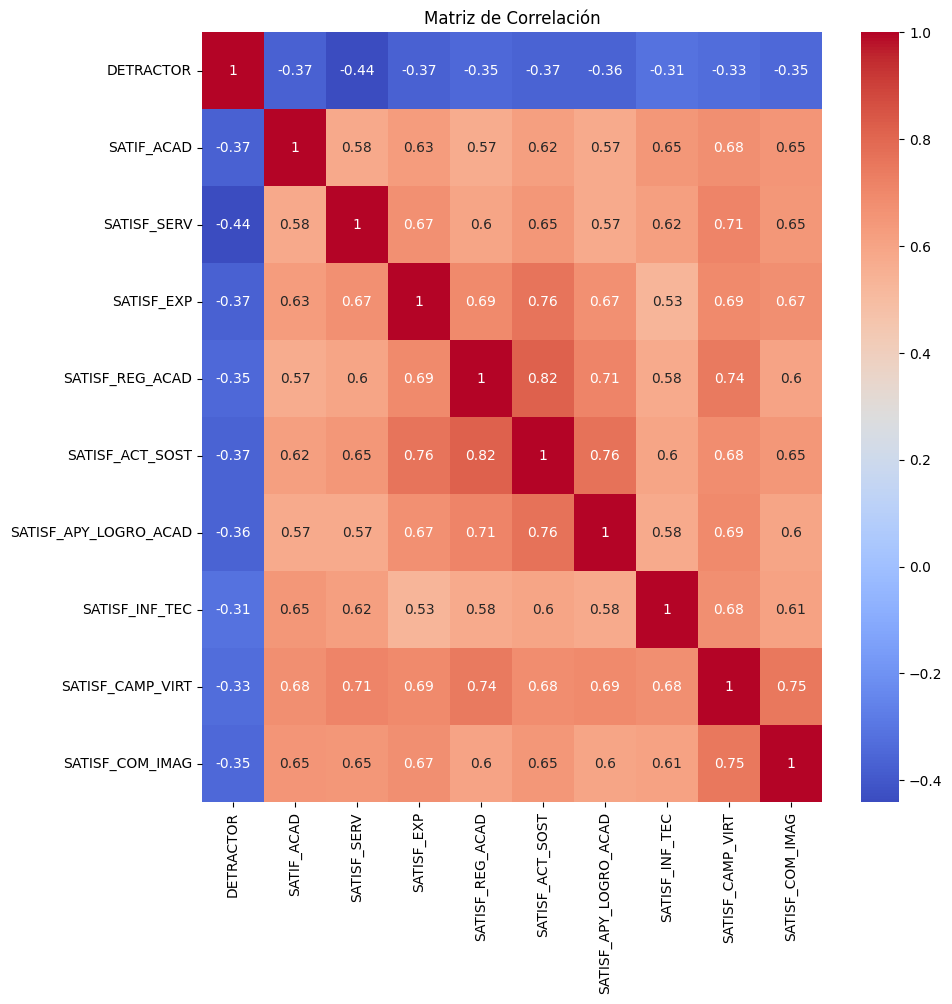

In [5]:
copia = X = estudiantes_CSOCIALES[['DETRACTOR', 'SATIF_ACAD', 'SATISF_SERV', 'SATISF_EXP', 'SATISF_REG_ACAD', 'SATISF_ACT_SOST', 'SATISF_APY_LOGRO_ACAD', 'SATISF_INF_TEC', 'SATISF_CAMP_VIRT', 'SATISF_COM_IMAG']]
plt.figure(figsize=(10, 10))
sns.heatmap(copia.corr(), annot=True, cmap='coolwarm')
plt.title('Matriz de Correlación')
plt.show()

**Preparación de conjuntos de extrenamiento y testing**

In [6]:
X = estudiantes_CSOCIALES[['SATIF_ACAD', 'SATISF_SERV', 'SATISF_EXP', 'SATISF_REG_ACAD', 'SATISF_ACT_SOST', 'SATISF_APY_LOGRO_ACAD', 'SATISF_INF_TEC', 'SATISF_CAMP_VIRT', 'SATISF_COM_IMAG']]
y = estudiantes_CSOCIALES['DETRACTOR']
XCopia = X.copy()

**Pruebas T de Diferencia de Medias para refinar las columnas del Modelo el conjunto final queda en XCopia**

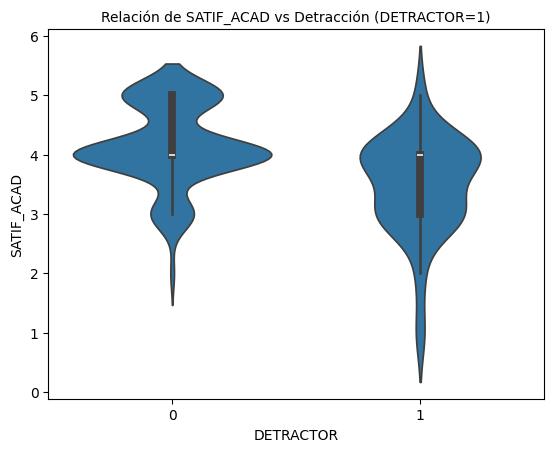

*** Prueba t para SATIF_ACAD ***
Estadístico t: -4.37865
Valor p: 0.00003
Se rechaza la hipótesis nula. Las medias son significativamente diferentes.
DETRACTOR
0    4.145833
1    3.481481
Name: SATIF_ACAD, dtype: float64




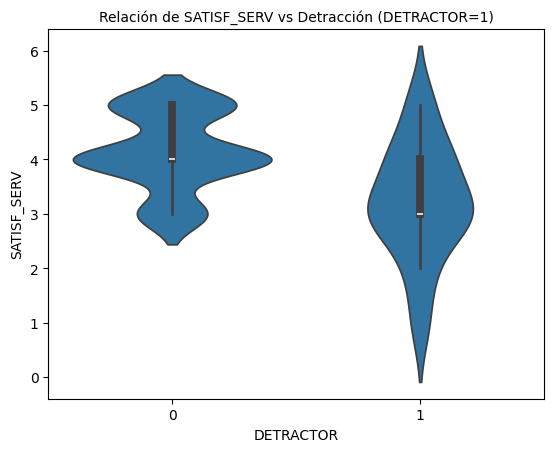

*** Prueba t para SATISF_SERV ***
Estadístico t: -5.39889
Valor p: 0.00000
Se rechaza la hipótesis nula. Las medias son significativamente diferentes.
DETRACTOR
0    4.145833
1    3.222222
Name: SATISF_SERV, dtype: float64




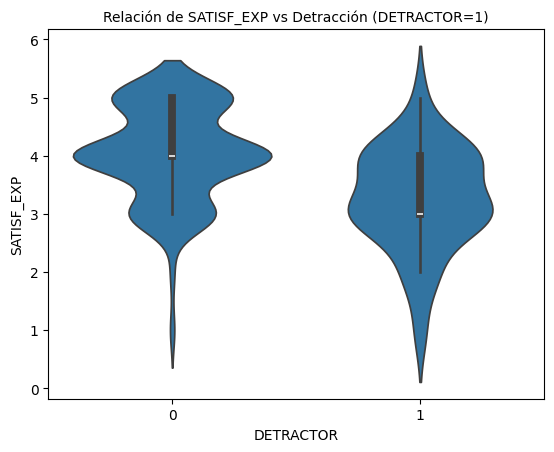

*** Prueba t para SATISF_EXP ***
Estadístico t: -4.35589
Valor p: 0.00003
Se rechaza la hipótesis nula. Las medias son significativamente diferentes.
DETRACTOR
0    4.031250
1    3.259259
Name: SATISF_EXP, dtype: float64




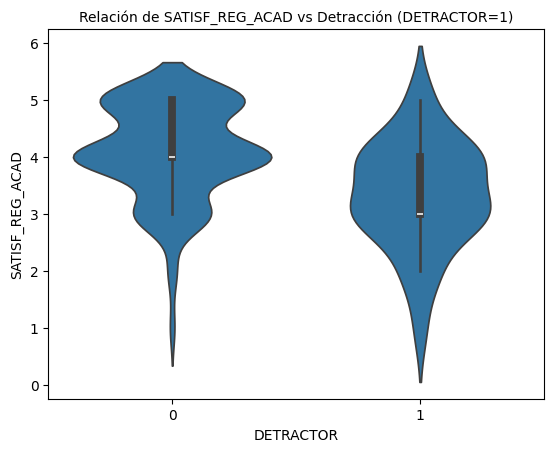

*** Prueba t para SATISF_REG_ACAD ***
Estadístico t: -4.05255
Valor p: 0.00009
Se rechaza la hipótesis nula. Las medias son significativamente diferentes.
DETRACTOR
0    4.083333
1    3.333333
Name: SATISF_REG_ACAD, dtype: float64




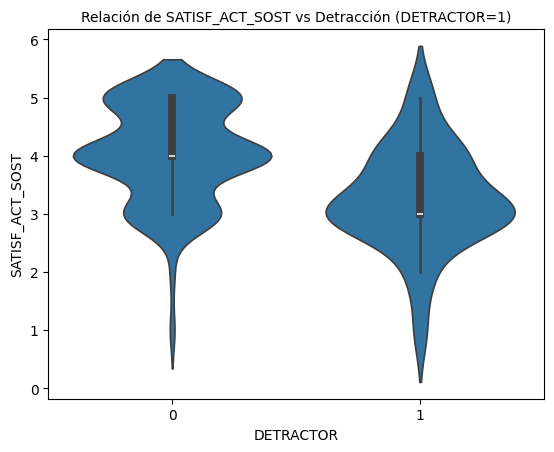

*** Prueba t para SATISF_ACT_SOST ***
Estadístico t: -4.33614
Valor p: 0.00003
Se rechaza la hipótesis nula. Las medias son significativamente diferentes.
DETRACTOR
0    4.041667
1    3.259259
Name: SATISF_ACT_SOST, dtype: float64




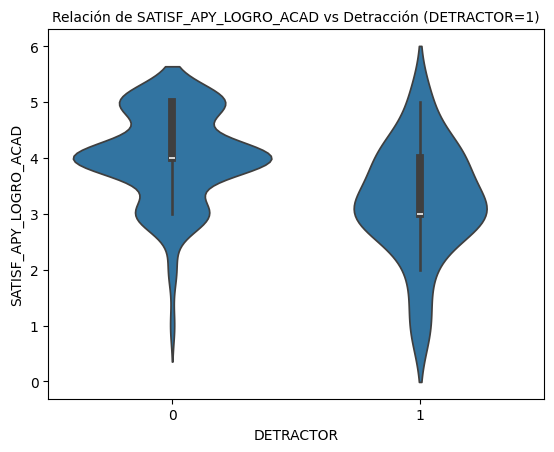

*** Prueba t para SATISF_APY_LOGRO_ACAD ***
Estadístico t: -4.30043
Valor p: 0.00003
Se rechaza la hipótesis nula. Las medias son significativamente diferentes.
DETRACTOR
0    4.010417
1    3.222222
Name: SATISF_APY_LOGRO_ACAD, dtype: float64




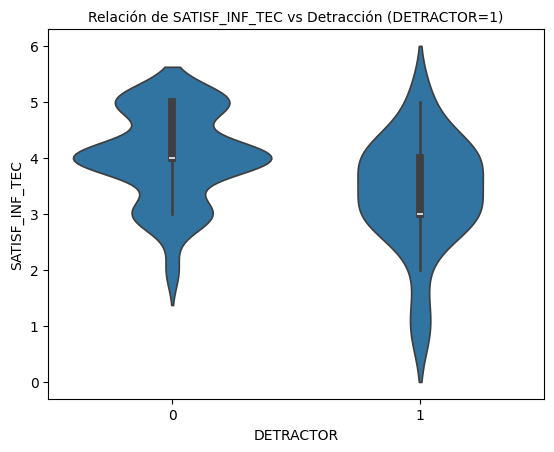

*** Prueba t para SATISF_INF_TEC ***
Estadístico t: -3.62160
Valor p: 0.00043
Se rechaza la hipótesis nula. Las medias son significativamente diferentes.
DETRACTOR
0    4.020833
1    3.370370
Name: SATISF_INF_TEC, dtype: float64




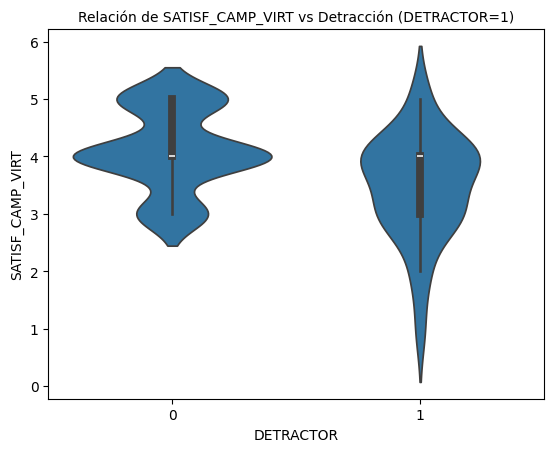

*** Prueba t para SATISF_CAMP_VIRT ***
Estadístico t: -3.87924
Valor p: 0.00017
Se rechaza la hipótesis nula. Las medias son significativamente diferentes.
DETRACTOR
0    4.104167
1    3.481481
Name: SATISF_CAMP_VIRT, dtype: float64




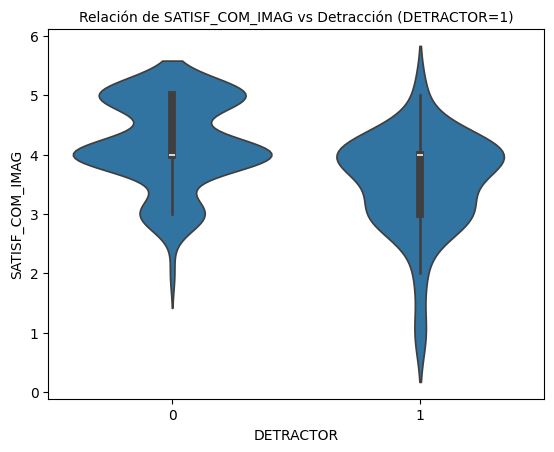

*** Prueba t para SATISF_COM_IMAG ***
Estadístico t: -4.07094
Valor p: 0.00008
Se rechaza la hipótesis nula. Las medias son significativamente diferentes.
DETRACTOR
0    4.177083
1    3.518519
Name: SATISF_COM_IMAG, dtype: float64




In [7]:
for column in X.columns:
    title = f"Relación de {column} vs Detracción (DETRACTOR=1)"
    ml.analisis_variable_violin(estudiantes_CSOCIALES, "DETRACTOR", column, title)
    ml.prueba_t(estudiantes_CSOCIALES, 'DETRACTOR', column, 1, 0, XCopia)

**Modelo de Regresión Logística para predecir Detractores**

Precisión del modelo con class_weight='balanced': 0.680
Reporte de clasificación con class_weight='balanced':
              precision    recall  f1-score   support

           0       0.80      0.80      0.80        20
           1       0.20      0.20      0.20         5

    accuracy                           0.68        25
   macro avg       0.50      0.50      0.50        25
weighted avg       0.68      0.68      0.68        25



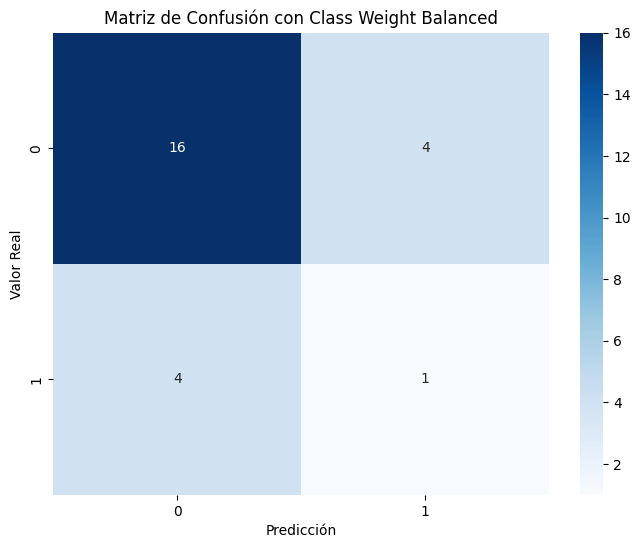

In [8]:
# Modelo de Regresión Logística con class_weight='balanced'
# Esto asignará automáticamente pesos inversamente proporcionales a las frecuencias de clase.

X_train, X_test, y_train, y_test = train_test_split(XCopia, y, test_size=0.20, random_state=42)

model_balanced = LogisticRegression(solver='liblinear', max_iter=300, random_state=50, class_weight='balanced')

model_balanced.fit(X_train, y_train)

y_pred_balanced = model_balanced.predict(X_test)
accuracy_balanced = accuracy_score(y_test, y_pred_balanced)
report_balanced = classification_report(y_test, y_pred_balanced)

print(f'Precisión del modelo con class_weight=\'balanced\': {accuracy_balanced:.3f}')
print(f'Reporte de clasificación con class_weight=\'balanced\':\n{report_balanced}')

# Graficar la matriz de confusión
plt.figure(figsize=(8, 6))
sns.heatmap(confusion_matrix(y_test, y_pred_balanced), annot=True, fmt='d', cmap='Blues')
plt.title('Matriz de Confusión con Class Weight Balanced')
plt.xlabel('Predicción')
plt.ylabel('Valor Real')
plt.show()

### **Análisis de la Importancia de las Variables (`model_balanced`)**

SATIF_ACAD: -0.21
SATISF_SERV: -0.53
SATISF_EXP: -0.04
SATISF_REG_ACAD: 0.17
SATISF_ACT_SOST: -0.57
SATISF_APY_LOGRO_ACAD: 0.15
SATISF_INF_TEC: 0.04
SATISF_CAMP_VIRT: 0.20
SATISF_COM_IMAG: 0.10


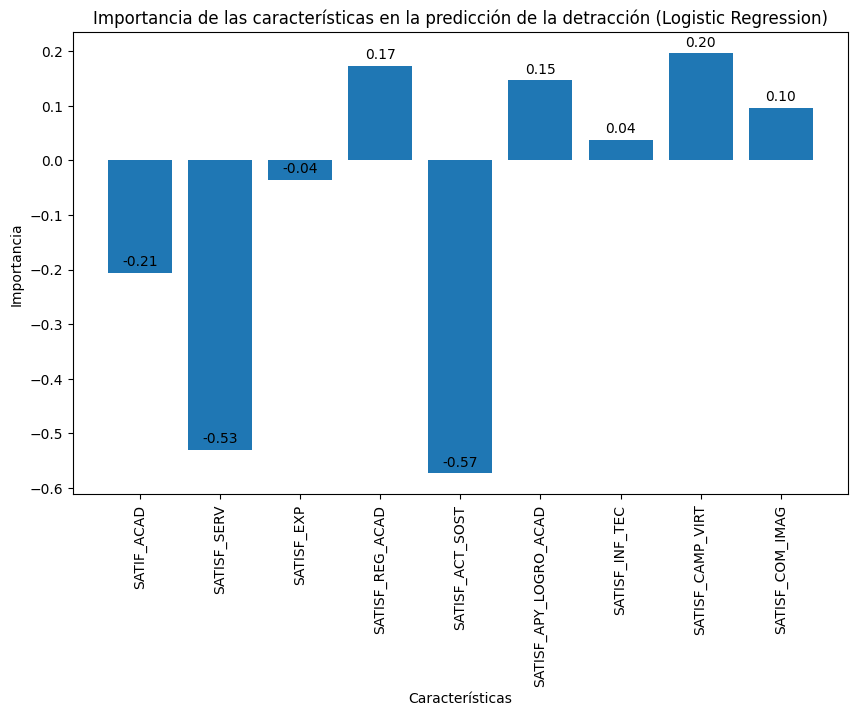

In [9]:
feature_importance = model_balanced.coef_[0]

for i in range(0, len(XCopia.columns)):
    print(f"{XCopia.columns[i]}: {feature_importance[i]:.2f}")

plt.figure(figsize=(10, 6))
bars = plt.bar(XCopia.columns, feature_importance)
plt.xlabel('Características')
plt.ylabel('Importancia')
plt.title('Importancia de las características en la predicción de la detracción (Logistic Regression)')

for bar in bars:
    height = bar.get_height()
    plt.annotate(f'{height:.2f}', xy=(bar.get_x() + bar.get_width() / 2, height),
                xytext=(0, 3), textcoords="offset points", ha='center', va='bottom')

plt.xticks(rotation=90)
plt.show()

### **Análisis SHAP para `model_balanced`**

  0%|          | 0/25 [00:00<?, ?it/s]

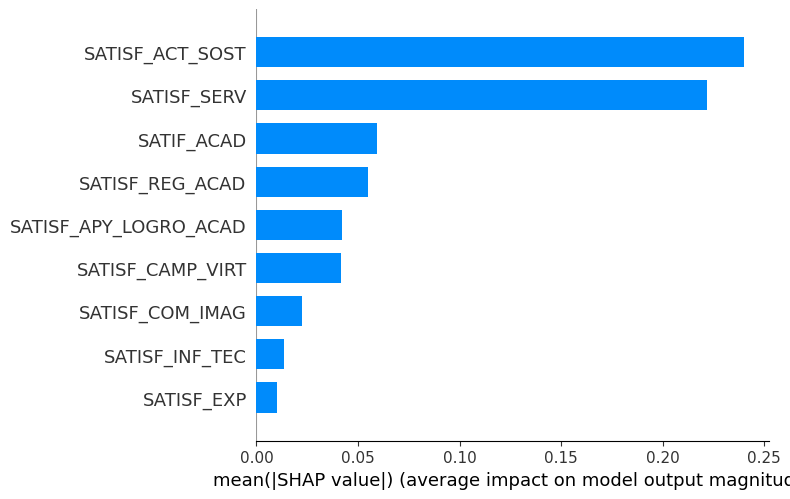

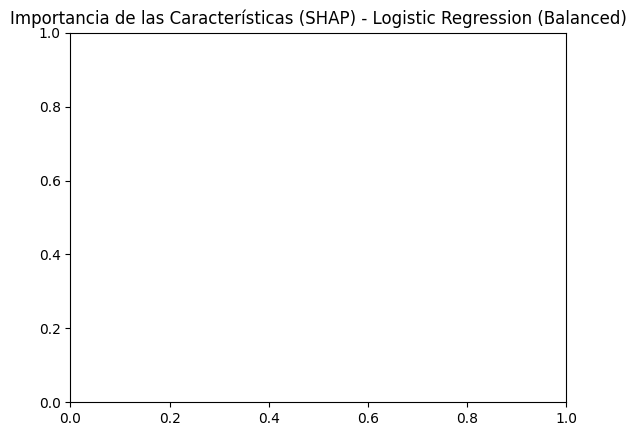

In [10]:
import shap

explainer = shap.KernelExplainer(model_balanced.predict, X_train)
shap_values = explainer.shap_values(X_test)

shap.summary_plot(shap_values, X_test, feature_names=XCopia.columns, plot_type="bar")
plt.title('Importancia de las Características (SHAP) - Logistic Regression (Balanced)')
plt.show()

**Análisis de Deep Learning para ver impacto de las variables en el modelo**

  0%|          | 0/25 [00:00<?, ?it/s]

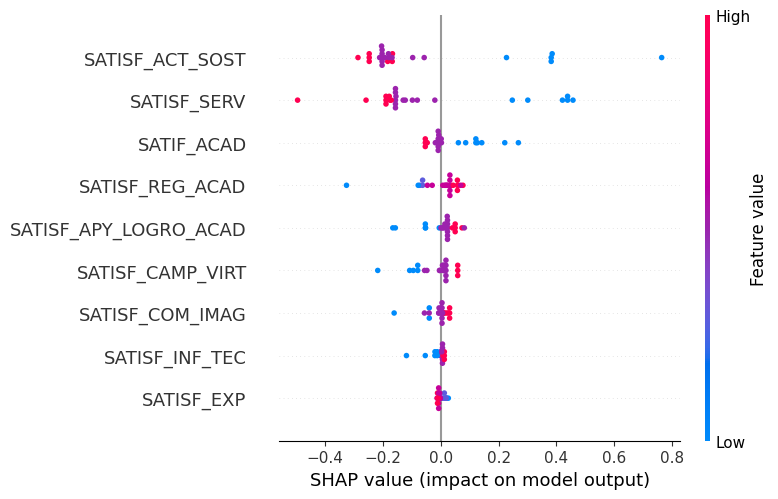

In [11]:
import shap

explainer = shap.KernelExplainer(model_balanced.predict, X_train)
shap_values = explainer.shap_values(X_test)

shap.summary_plot(shap_values, X_test, feature_names=XCopia.columns)

# **Análisis de los factores de Satisfacción lo académico**
**P3. ¿QUÉ TAN SATISFECHO TE ENCUENTRAS CON EL ÁREA ACADÉMICA DE LA UNIVERSIDAD CONTINENTAL?**

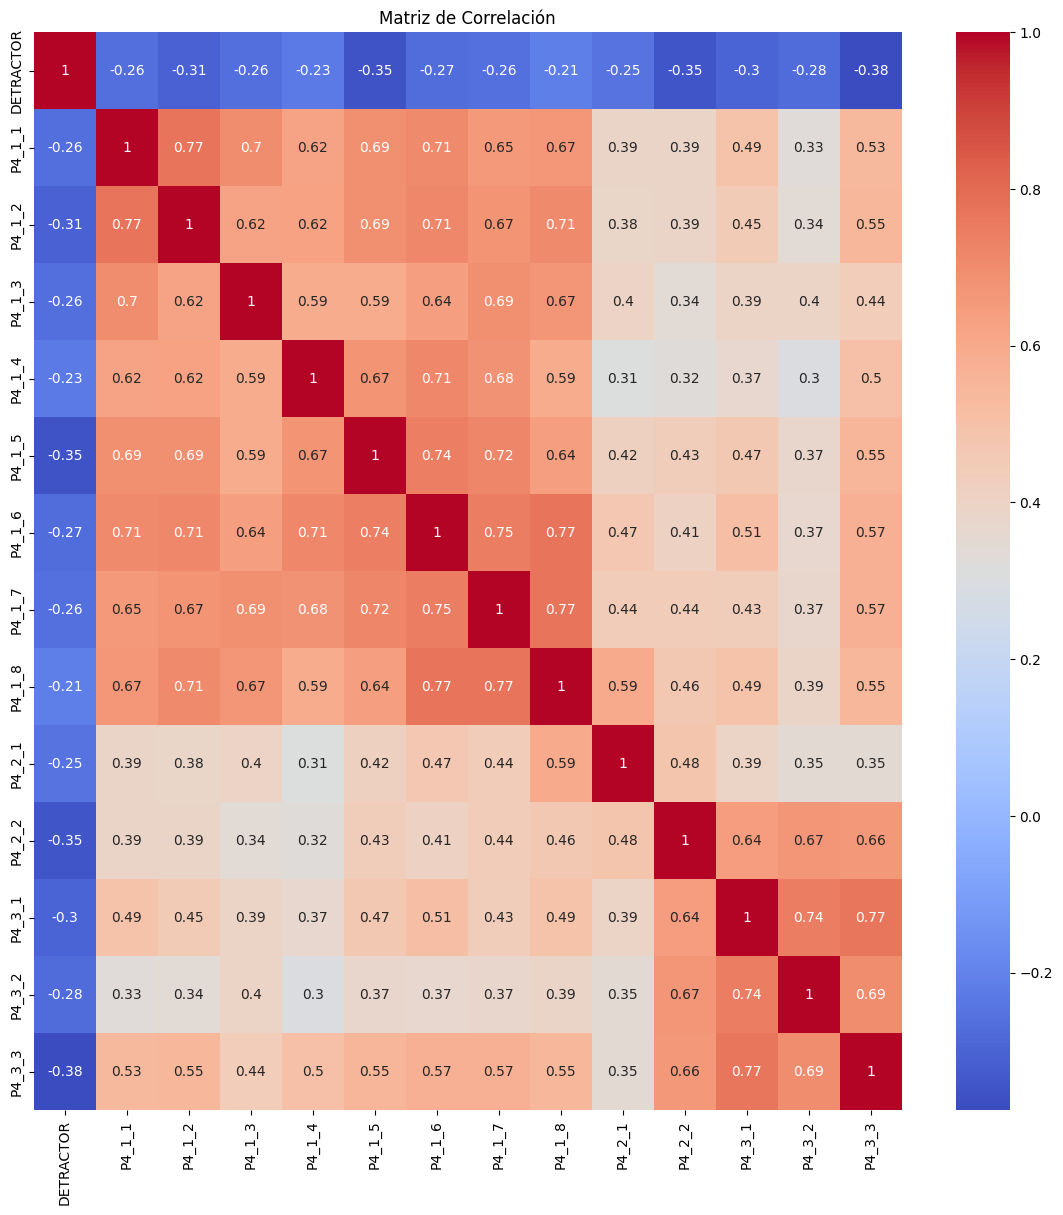

In [12]:
copia = X = estudiantes_CSOCIALES[['DETRACTOR','P4_1_1','P4_1_2','P4_1_3','P4_1_4','P4_1_5','P4_1_6','P4_1_7','P4_1_8','P4_2_1','P4_2_2','P4_3_1','P4_3_2','P4_3_3']]
plt.figure(figsize=(14, 14))
sns.heatmap(copia.corr(), annot=True, cmap='coolwarm')
plt.title('Matriz de Correlación')
plt.show()

In [13]:
X = estudiantes_CSOCIALES[['P4_1_1','P4_1_2','P4_1_3','P4_1_4','P4_1_5','P4_1_6','P4_1_7','P4_1_8','P4_2_1','P4_2_2','P4_3_1','P4_3_2','P4_3_3']]
y = estudiantes_CSOCIALES['DETRACTOR']
XCopia = X.copy()

**Pruebas T de Diferencia de Medias para refinar las columnas del Modelo el conjunto final queda en XCopia**

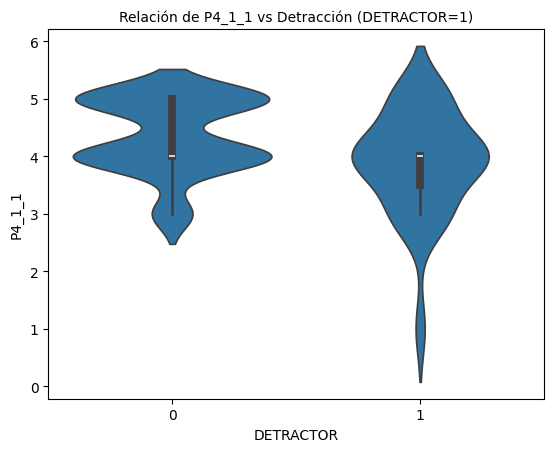

*** Prueba t para P4_1_1 ***
Estadístico t: -3.01748
Valor p: 0.00311
Se rechaza la hipótesis nula. Las medias son significativamente diferentes.
DETRACTOR
0    4.354167
1    3.888889
Name: P4_1_1, dtype: float64




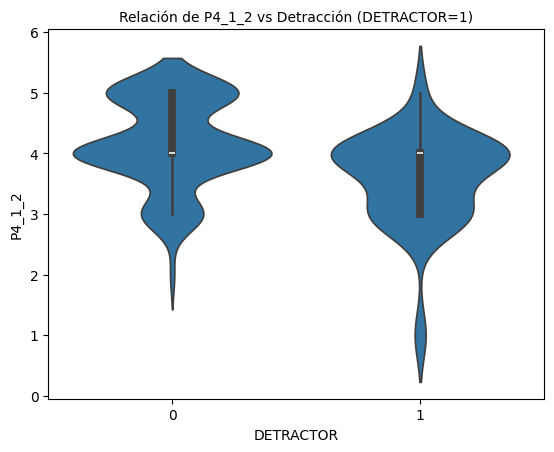

*** Prueba t para P4_1_2 ***
Estadístico t: -3.58097
Valor p: 0.00049
Se rechaza la hipótesis nula. Las medias son significativamente diferentes.
DETRACTOR
0    4.156250
1    3.592593
Name: P4_1_2, dtype: float64




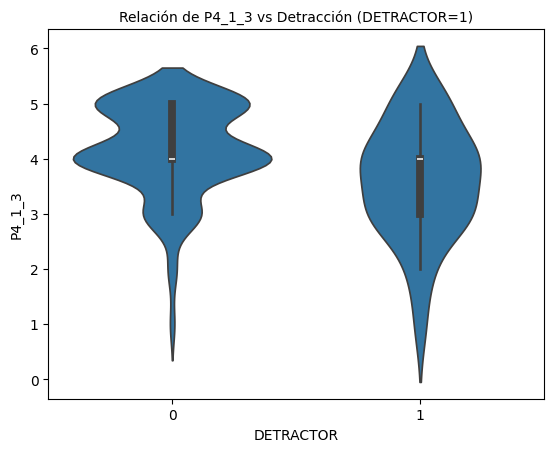

*** Prueba t para P4_1_3 ***
Estadístico t: -3.01406
Valor p: 0.00314
Se rechaza la hipótesis nula. Las medias son significativamente diferentes.
DETRACTOR
0    4.156250
1    3.592593
Name: P4_1_3, dtype: float64




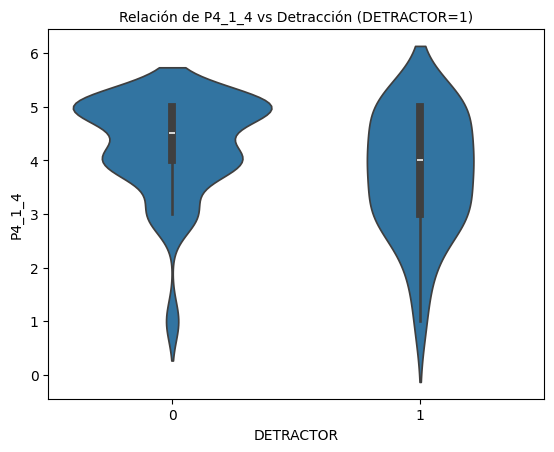

*** Prueba t para P4_1_4 ***
Estadístico t: -2.59537
Valor p: 0.01062
Se rechaza la hipótesis nula. Las medias son significativamente diferentes.
DETRACTOR
0    4.281250
1    3.740741
Name: P4_1_4, dtype: float64




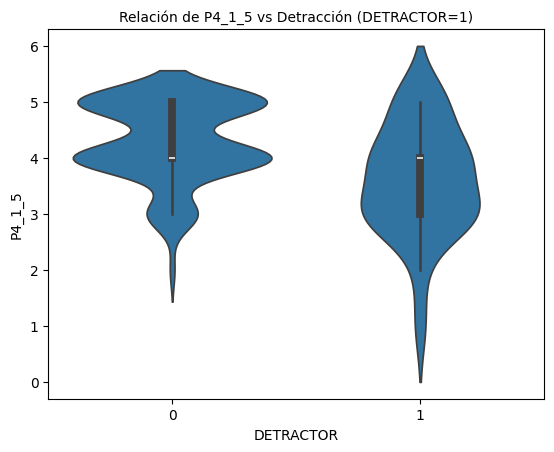

*** Prueba t para P4_1_5 ***
Estadístico t: -4.15008
Valor p: 0.00006
Se rechaza la hipótesis nula. Las medias son significativamente diferentes.
DETRACTOR
0    4.291667
1    3.592593
Name: P4_1_5, dtype: float64




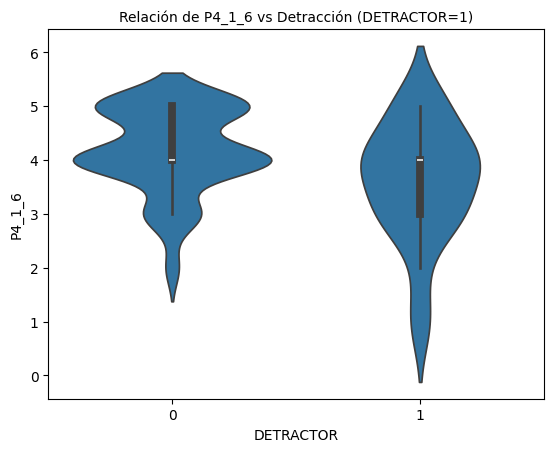

*** Prueba t para P4_1_6 ***
Estadístico t: -3.09279
Valor p: 0.00246
Se rechaza la hipótesis nula. Las medias son significativamente diferentes.
DETRACTOR
0    4.166667
1    3.592593
Name: P4_1_6, dtype: float64




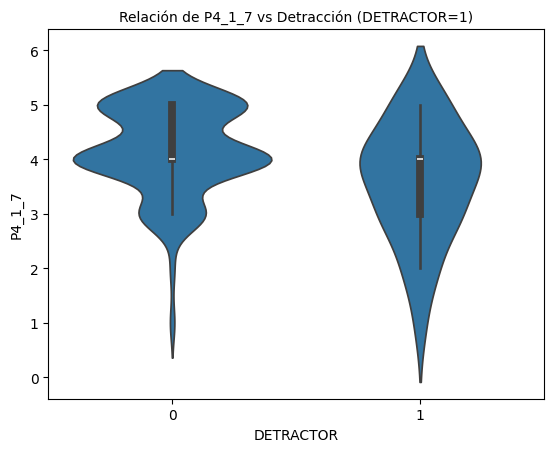

*** Prueba t para P4_1_7 ***
Estadístico t: -2.97000
Valor p: 0.00359
Se rechaza la hipótesis nula. Las medias son significativamente diferentes.
DETRACTOR
0    4.145833
1    3.592593
Name: P4_1_7, dtype: float64




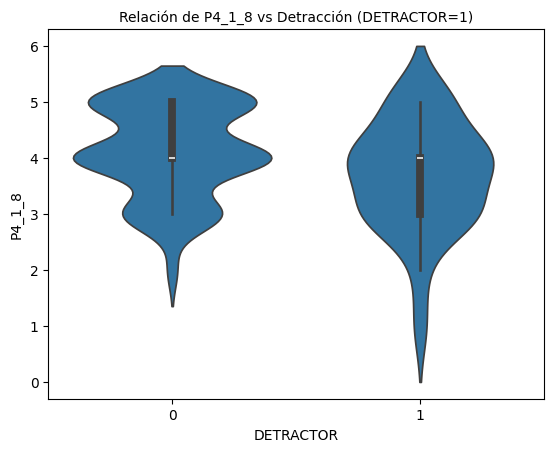

*** Prueba t para P4_1_8 ***
Estadístico t: -2.39680
Valor p: 0.01807
Se rechaza la hipótesis nula. Las medias son significativamente diferentes.
DETRACTOR
0    4.104167
1    3.666667
Name: P4_1_8, dtype: float64




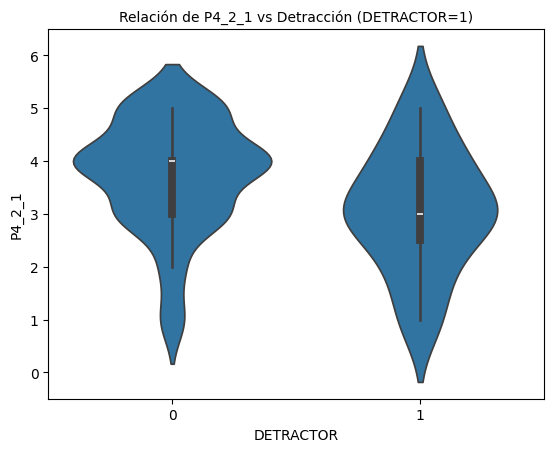

*** Prueba t para P4_2_1 ***
Estadístico t: -2.82814
Valor p: 0.00548
Se rechaza la hipótesis nula. Las medias son significativamente diferentes.
DETRACTOR
0    3.729167
1    3.074074
Name: P4_2_1, dtype: float64




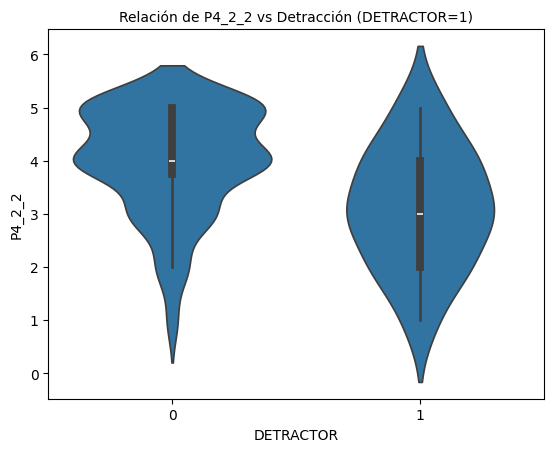

*** Prueba t para P4_2_2 ***
Estadístico t: -4.05110
Valor p: 0.00009
Se rechaza la hipótesis nula. Las medias son significativamente diferentes.
DETRACTOR
0    4.010417
1    3.111111
Name: P4_2_2, dtype: float64




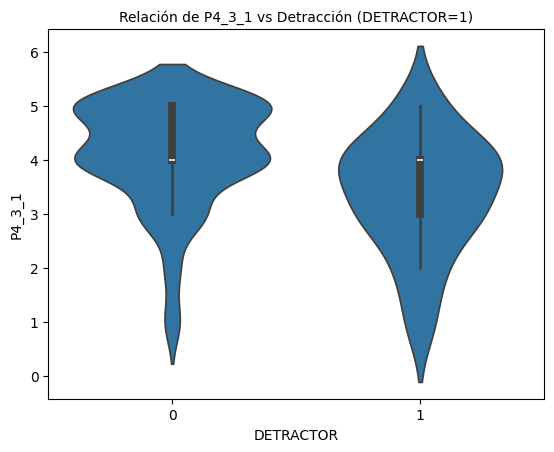

*** Prueba t para P4_3_1 ***
Estadístico t: -3.43004
Valor p: 0.00083
Se rechaza la hipótesis nula. Las medias son significativamente diferentes.
DETRACTOR
0    4.114583
1    3.370370
Name: P4_3_1, dtype: float64




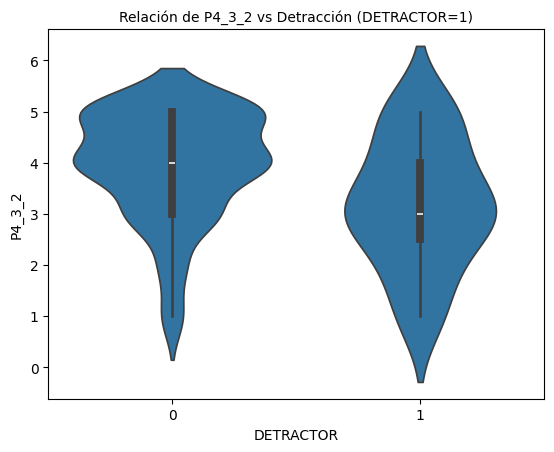

*** Prueba t para P4_3_2 ***
Estadístico t: -3.17867
Valor p: 0.00188
Se rechaza la hipótesis nula. Las medias son significativamente diferentes.
DETRACTOR
0    3.947917
1    3.185185
Name: P4_3_2, dtype: float64




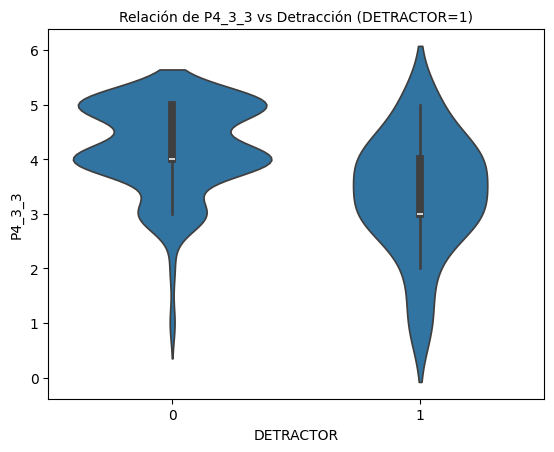

*** Prueba t para P4_3_3 ***
Estadístico t: -4.45706
Valor p: 0.00002
Se rechaza la hipótesis nula. Las medias son significativamente diferentes.
DETRACTOR
0    4.208333
1    3.370370
Name: P4_3_3, dtype: float64




In [14]:
for column in X.columns:
    title = f"Relación de {column} vs Detracción (DETRACTOR=1)"
    ml.analisis_variable_violin(estudiantes_CSOCIALES, "DETRACTOR", column, title)
    ml.prueba_t(estudiantes_CSOCIALES, 'DETRACTOR', column, 1, 0, XCopia)

Precisión del modelo con class_weight='balanced': 0.703
Reporte de clasificación con class_weight='balanced':
              precision    recall  f1-score   support

           0       0.88      0.74      0.81        31
           1       0.27      0.50      0.35         6

    accuracy                           0.70        37
   macro avg       0.58      0.62      0.58        37
weighted avg       0.79      0.70      0.73        37



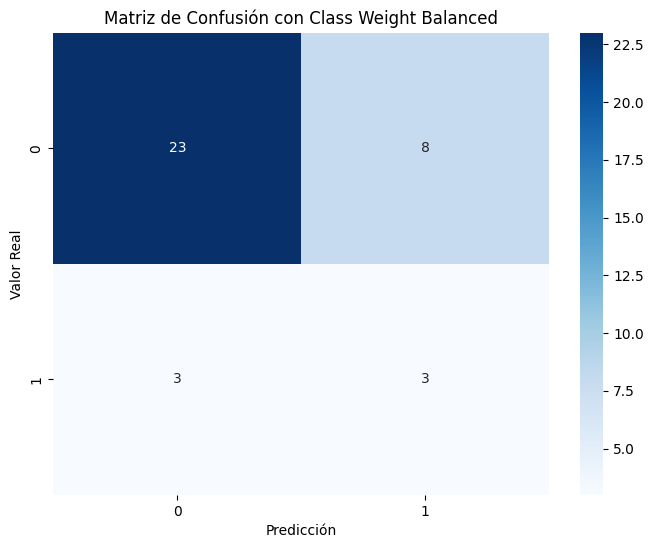

In [15]:
# Modelo de Regresión Logística con class_weight='balanced'
# Esto asignará automáticamente pesos inversamente proporcionales a las frecuencias de clase.

X_train, X_test, y_train, y_test = train_test_split(XCopia, y, test_size=0.3, random_state=42)

model_balanced = LogisticRegression(solver='liblinear', max_iter=300, random_state=50, class_weight='balanced')

model_balanced.fit(X_train, y_train)

y_pred_balanced = model_balanced.predict(X_test)
accuracy_balanced = accuracy_score(y_test, y_pred_balanced)
report_balanced = classification_report(y_test, y_pred_balanced)

print(f'Precisión del modelo con class_weight=\'balanced\': {accuracy_balanced:.3f}')
print(f'Reporte de clasificación con class_weight=\'balanced\':\n{report_balanced}')

# Graficar la matriz de confusión
plt.figure(figsize=(8, 6))
sns.heatmap(confusion_matrix(y_test, y_pred_balanced), annot=True, fmt='d', cmap='Blues')
plt.title('Matriz de Confusión con Class Weight Balanced')
plt.xlabel('Predicción')
plt.ylabel('Valor Real')
plt.show()

**4.1.8 EL SEGUIMIENTO DEL DESEMPEÑO DEL ESTUDIANTE ACOMPAÑADO DE RETROALIMENTACIÓN CONSTRUCTIVA SOBRE TRABAJOS, PROYECTOS Y ENTREGABLES**

**4.3.1 FLEXIBILIDAD PARA LA ELECCIÓN DE ASIGNATURAS DEL PLAN DE ESTUDIOS**

**4.3.3 LAS ASIGNATURAS DEL PLAN DE ESTUDIOS PERMITEN EL LOGRO DE LAS COMPETENCIAS DE LA CARRERA QUE CURSAN LOS ESTUDIANTES**

  0%|          | 0/37 [00:00<?, ?it/s]

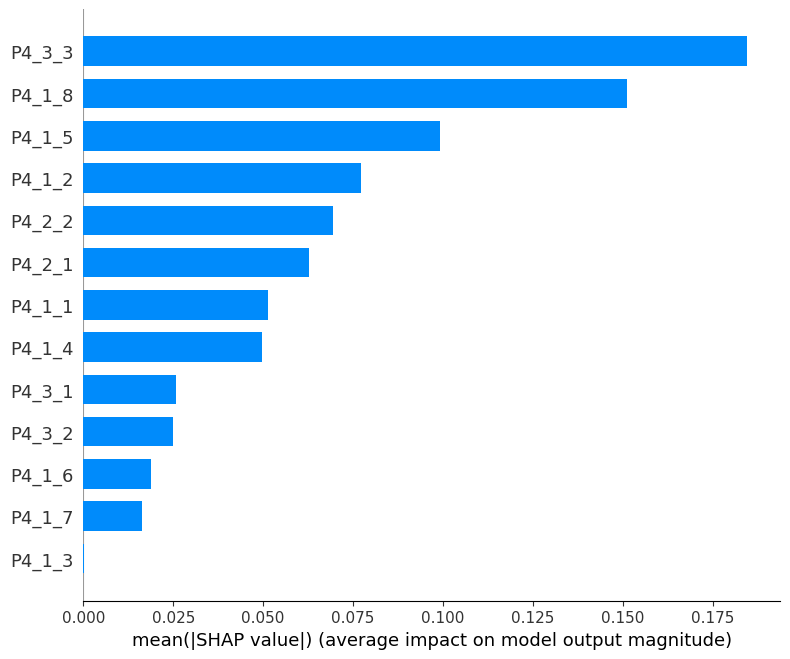

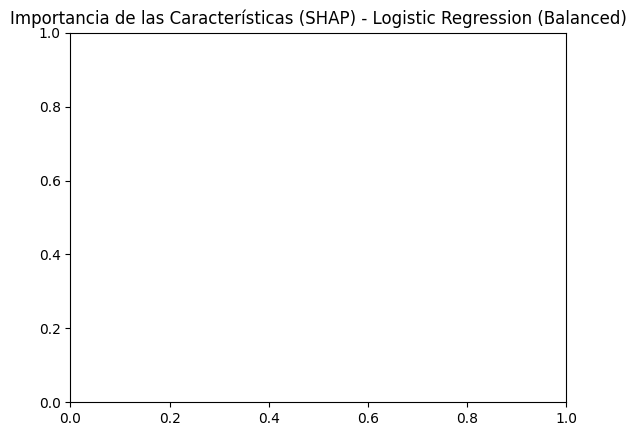

In [16]:
import shap

explainer = shap.KernelExplainer(model_balanced.predict, X_train)
shap_values = explainer.shap_values(X_test)

shap.summary_plot(shap_values, X_test, feature_names=XCopia.columns, plot_type="bar")
plt.title('Importancia de las Características (SHAP) - Logistic Regression (Balanced)')
plt.show()

**Si ves puntos rojos en el lado izquierdo y azules en el derecho esto significa valores altos de la característica disminuyen la probabilidad de ser detractor y valores bajos la aumentan**

  0%|          | 0/37 [00:00<?, ?it/s]

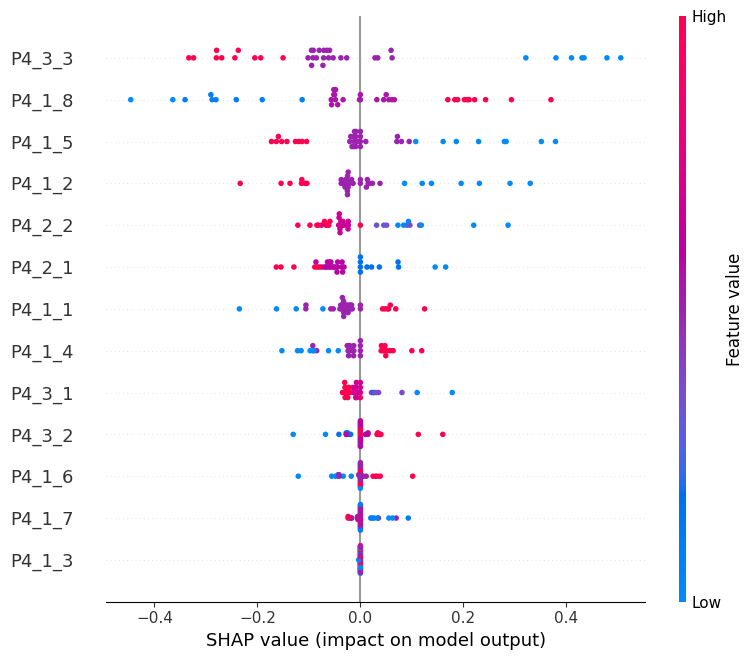

In [17]:
explainer = shap.KernelExplainer(model_balanced.predict, X_train)
shap_values = explainer.shap_values(X_test)

shap.summary_plot(shap_values, X_test, feature_names=XCopia.columns)